<a href="https://colab.research.google.com/github/gissinu16-nunez/Student-Performance-Factors-Analysis-Predictive-Insights/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Performance Factors: Analysis & Predictive Insights
This notebook walks through a comprehensive analysis of various factors affecting student exam performance—including data cleaning, behavioral metrics exploration, data visualization, and descriptive statistical analysis.

In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "StudentPerformanceFactors.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "lainguyn123/student-performance-factors",
  file_path,

)

print("First 5 records:")
print(df.head())

Using Colab cache for faster access to the 'student-performance-factors' dataset.
First 5 records:
   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65         

### Section 1: Data Inspection

In [14]:
import pandas as pd
df.info()

missing_vals = df.isnull().sum()

display(missing_vals[missing_vals > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6607 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

,0


### Section 2: Handling Missing Values
Impute missing values:
* For categorical columns (`object`), I filled missing entries with the column's **mode** (most frequent value).
* For numerical columns, i filled missing entries with the column's **median**.

In [3]:
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == 'object':
            mode_val = df[col].mode()[0]
            df[col] = df[col].fillna(mode_val)
            print(f"Filled missing values in categorical column '{col}' with mode: {mode_val}")
        else:
            median_val = df[col].median()
            df[col] = df[col].fillna(median_val)
            print(f"Filled missing values in numerical column '{col}' with median: {median_val}")

Filled missing values in categorical column 'Teacher_Quality' with mode: Medium
Filled missing values in categorical column 'Parental_Education_Level' with mode: High School
Filled missing values in categorical column 'Distance_from_Home' with mode: Near


### Section 3: Check and Remove Duplicates
Checked if any identical records exist and drop them to prevent skewed analyses.

In [4]:
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicates_count}")

if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Duplicate rows have been successfully removed.")

Number of duplicate rows found: 0


### Section 4: Text Standardization and Verification

In [5]:
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.strip()

print("--- Final Cleaned Dataset Info ---")
df.info()

print("\nFirst 5 cleaned records:")
display(df.head())

--- Final Cleaned Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6607 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influenc

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


### Section 5: Dataset Manipulation (Filtering, Grouping, and Sorting)
 I filtered the students with an attendance rate of greater than 85% and group them by their parental involvement level to see how average hours studied and final exam scores compare.

In [6]:
high_attendance_df = df[df['Attendance'] > 85]

manipulated_df = high_attendance_df.groupby('Parental_Involvement').agg(
    Average_Hours_Studied=('Hours_Studied', 'mean'),
    Average_Previous_Score=('Previous_Scores', 'mean'),
    Average_Exam_Score=('Exam_Score', 'mean'),
    Student_Count=('Exam_Score', 'count')
).reset_index()

manipulated_df = manipulated_df.sort_values(by='Average_Exam_Score', ascending=False)

print("Manipulated Dataset (High Attendance Students Grouped by Parental Involvement):")
display(manipulated_df)

Manipulated Dataset (High Attendance Students Grouped by Parental Involvement):


,Parental_Involvement,Average_Hours_Studied,Average_Previous_Score,Average_Exam_Score,Student_Count
0,High,19.865185,74.136296,70.731852,675
2,Medium,20.041246,74.660774,69.664983,1188
1,Low,20.195219,74.846614,68.896414,502


### Section 6: Visualization 1
**Distribution of Exam Scores by Gender**  
This plot displays how the final exam scores are distributed between male and female students in the dataset using an overlaid histogram with Kernel Density Estimation (KDE) curves.

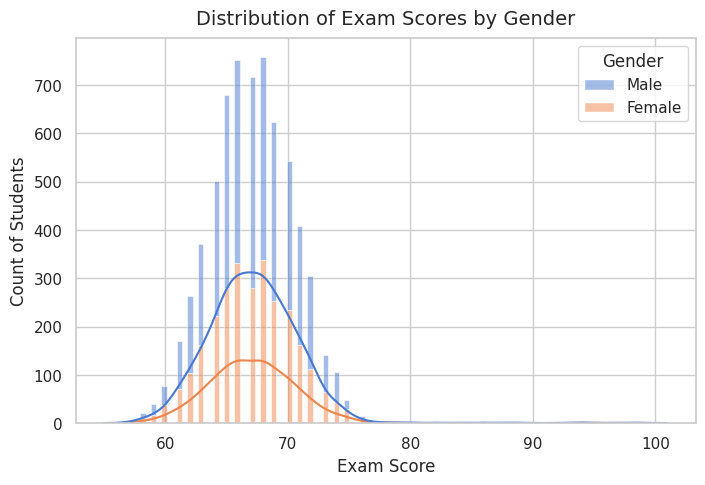

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="Exam_Score",
    hue="Gender",
    kde=True,
    multiple="stack",
    palette="muted"
)
plt.title("Distribution of Exam Scores by Gender", fontsize=14, pad=10)
plt.xlabel("Exam Score", fontsize=12)
plt.ylabel("Count of Students", fontsize=12)
plt.show()

### Section 7: Visualization 2
**Exam Scores across Parental Involvement Levels**  
This plot displays the distribution and median of final exam scores across the three parental involvement tiers: Low, Medium, and High.

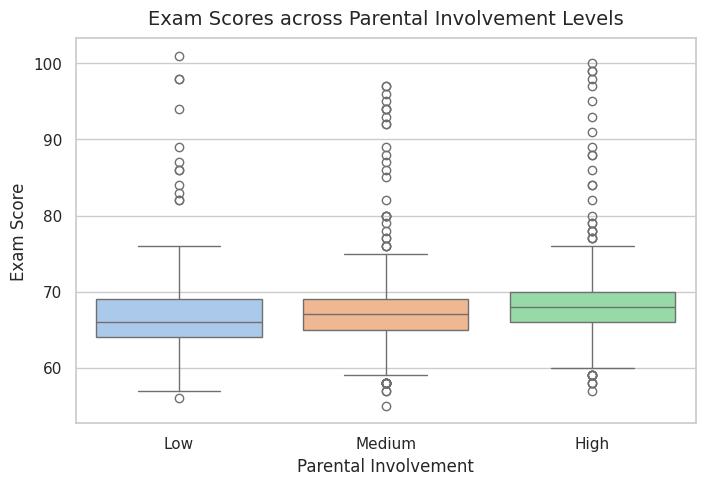

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Parental_Involvement",
    y="Exam_Score",
    hue="Parental_Involvement",
    order=["Low", "Medium", "High"],
    palette="pastel",
    legend=False
)
plt.title("Exam Scores across Parental Involvement Levels", fontsize=14, pad=10)
plt.xlabel("Parental Involvement", fontsize=12)
plt.ylabel("Exam Score", fontsize=12)
plt.show()

### Section 8: Visualization 3
**Correlation Heatmap**  
This visualization demonstrates the relationships and correlation strengths between all numerical parameters in the dataset.

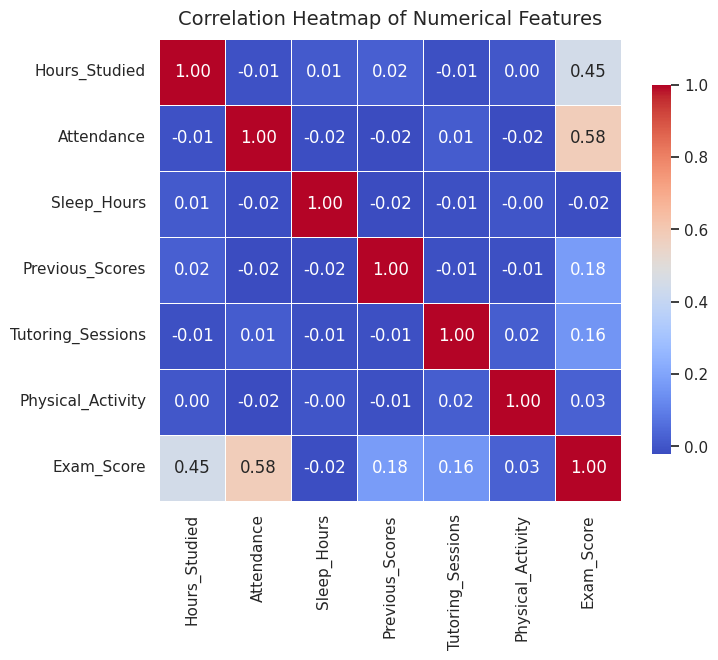

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = df.select_dtypes(include=['int64', 'float64'])
corr_matrix = numerical_cols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, pad=10)
plt.show()

### Section 9: Statistical Analysis
In this section, i did a detailed statistical analysis of the student performance dataset.

In [10]:
numerical_cols = df.select_dtypes(include=['int64', 'float64'])
descriptive_stats = numerical_cols.describe().T

descriptive_stats['median'] = numerical_cols.median()
descriptive_stats['mode'] = numerical_cols.mode().iloc[0]
descriptive_stats['std_dev'] = numerical_cols.std()

print("--- Descriptive Statistics (Numerical Features) ---")
display(descriptive_stats[['mean', 'median', 'mode', 'std_dev', 'min', 'max']])

--- Descriptive Statistics (Numerical Features) ---


,mean,median,mode,std_dev,min,max
Hours_Studied,19.975329,20.0,20,5.990594,1.0,44.0
Attendance,79.977448,80.0,67,11.547475,60.0,100.0
Sleep_Hours,7.029060,7.0,7,1.468120,4.0,10.0
Previous_Scores,75.070531,75.0,66,14.399784,50.0,100.0
Tutoring_Sessions,1.493719,1.0,1,1.230570,0.0,8.0
Physical_Activity,2.967610,3.0,3,1.031231,0.0,6.0
Exam_Score,67.235659,67.0,68,3.890456,55.0,101.0


In [11]:
print("--- Distribution Analysis (Skewness & Kurtosis) ---")
for col in numerical_cols.columns:
    skew_val = df[col].skew()
    kurt_val = df[col].kurt()
    print(f"{col:25} | Skewness: {skew_val:6.3f} | Kurtosis: {kurt_val:6.3f}")

--- Distribution Analysis (Skewness & Kurtosis) ---
Hours_Studied             | Skewness:  0.013 | Kurtosis:  0.018
Attendance                | Skewness:  0.014 | Kurtosis: -1.194
Sleep_Hours               | Skewness: -0.024 | Kurtosis: -0.504
Previous_Scores           | Skewness: -0.004 | Kurtosis: -1.191
Tutoring_Sessions         | Skewness:  0.816 | Kurtosis:  0.644
Physical_Activity         | Skewness: -0.031 | Kurtosis: -0.059
Exam_Score                | Skewness:  1.645 | Kurtosis: 10.575


In [15]:
correlations = numerical_cols.corr()['Exam_Score'].sort_values(ascending=False)
display(correlations)

,Exam_Score
Exam_Score,1.000000
Attendance,0.581072
Hours_Studied,0.445455
Previous_Scores,0.175079
Tutoring_Sessions,0.156525
Physical_Activity,0.027824
Sleep_Hours,-0.017022
